# Worked example: structural redundancy of ESR1 LBD structures

This notebook only **loads saved outputs**; nothing is recomputed from raw structures. It reproduces the main redundancy figure (cumulative diversity curve) and the 90% saturation numbers.

Run from the repository root:

```bash
python -m jupyter nbconvert --to notebook --execute notebooks/worked_example.ipynb --output worked_example.ipynb
```

Inputs: `results/rmsd_entry.npy` (S04, 788 x 788 C-alpha RMSD), `results/entry_clusters.csv` (S08), `results/diversity_curve.csv` (R02), `results/saturation.csv` (R04).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'results').is_dir():  # started from notebooks/
    ROOT = ROOT.parent
results = ROOT / 'results'

## 1. The saved RMSD matrix and the clusters

One row per eligible ESR1 chain; the matrix is loaded, never recomputed.

In [2]:
matrix = np.load(results / 'rmsd_entry.npy')
clusters = pd.read_csv(results / 'entry_clusters.csv')
assert matrix.shape == (len(clusters), len(clusters))
upper = np.triu_indices(len(matrix), 1)
print(f'{len(clusters)} chains from {clusters.entry_id.nunique()} entries; '
      f'median pairwise RMSD {np.median(matrix[upper]):.2f} A')
pd.DataFrame({cut: clusters[f'cut_{cut}'].value_counts().sort_values(ascending=False).tolist()[:5]
              for cut in ['1.0', '1.5', '2.0', '2.5']}.items(), columns=['cut (A)', 'five largest clusters (chains)'])

788 chains from 351 entries; median pairwise RMSD 1.35 A


,cut (A),five largest clusters (chains)
0,1.0,"[442, 262, 48, 11, 4]"
1,1.5,"[445, 329, 5, 3, 3]"
2,2.0,"[445, 336, 5, 2]"
3,2.5,"[447, 336, 5]"


## 2. 90% saturation N

The smallest number of chains, in random order, that shows on average 90% of all clusters (100 orderings).

In [3]:
curve = pd.read_csv(results / 'diversity_curve.csv', dtype={'cut': str})
rows = []
for cut, part in curve.groupby('cut', sort=False):
    total = int(part.n_clusters_total.iloc[0])
    n_90 = int(part.n[part.mean_clusters >= 0.9 * total].iloc[0])
    rows.append({'cut': cut, 'clusters': total, 'n_90': n_90, 'share_of_chains': n_90 / part.n.max()})
recomputed = pd.DataFrame(rows)
saved = pd.read_csv(results / 'saturation.csv', dtype={'cut': str})
assert (recomputed.n_90.to_numpy() == saved.n_90.to_numpy()).all(), 'n_90 differs from results/saturation.csv'
recomputed

,cut,clusters,n_90,share_of_chains
0,1.0,16,520,0.659898
1,1.5,7,488,0.619289
2,2.0,4,315,0.399746
3,2.5,3,147,0.186548


## 3. Main figure: cumulative diversity

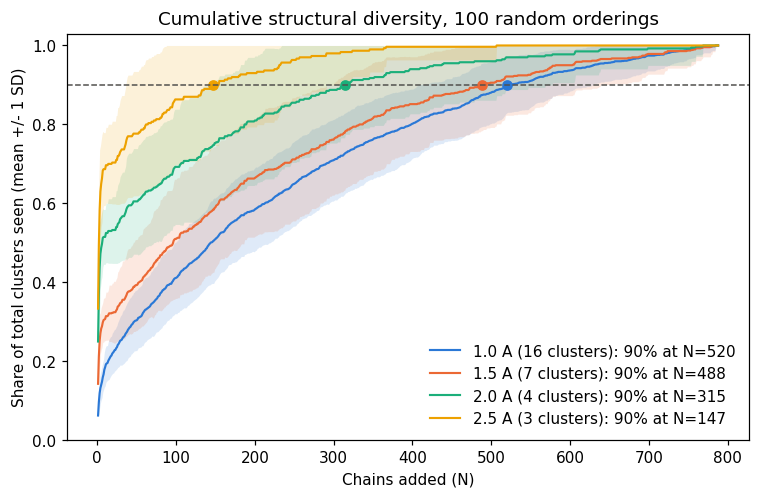

In [4]:
colours = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
fig, ax = plt.subplots(figsize=(8, 4.8), dpi=110)
for colour, row in zip(colours, recomputed.itertuples()):
    part = curve[curve.cut == row.cut]
    mean, sd = part.mean_clusters / row.clusters, part.sd_clusters / row.clusters
    ax.fill_between(part.n, (mean - sd).clip(lower=0), (mean + sd).clip(upper=1), color=colour, alpha=0.15, lw=0)
    ax.plot(part.n, mean, color=colour, lw=1.4, label=f'{row.cut} A ({row.clusters} clusters): 90% at N={row.n_90}')
    ax.plot([row.n_90], [0.9], 'o', color=colour)
ax.axhline(0.9, color='#52514e', ls='--', lw=1)
ax.set(xlabel='Chains added (N)', ylabel='Share of total clusters seen (mean +/- 1 SD)', ylim=(0, 1.03),
       title='Cumulative structural diversity, 100 random orderings')
ax.legend(frameon=False, loc='lower right')
plt.show()

## Reading

At the primary 1.5 A cut the 788 chains fall into 7 clusters, and the two largest hold almost all chains. Reaching 90% of the clusters still takes many chains, because the remaining clusters are tiny and found late. Coordinates are C-alpha only (see `docs/limitations.md`); QC sensitivity is in `results/qc_clustering_delta.csv`.